# 03 — Random Forest: Improvements, Comparison and Cost-Based Error Analysis

## What are we trying to do?

We want to find out whether **Random Forest** can make fewer costly mistakes than the group's **Logistic Regression** and a simple Dummy baseline. Our main measure is **total classification cost = 10 × FP + 500 × FN**. Missing a real APS failure (FN) therefore costs 50 times more than sending a false alarm (FP).

**Important:** We only read `aps_failure_training_set.csv` here. The official test set is saved for the group's final evaluation. We use the same stratified 80/20 split (`random_state=42`) as `02_eda_baseline.ipynb`.

### What do we try to improve?

1. **Decision threshold:** try different probability cutoffs instead of always using 0.5.
2. **Class weights:** test whether giving APS failures extra weight helps.
3. **Tree depth:** compare shallower and deeper trees to limit overfitting.

We compare **four simple Random Forest settings**, not hundreds of combinations. We choose both the model and its threshold using a separate calibration set. The final internal validation set is only used **after** those choices are fixed.


## 1. Imports and fixed settings

A fixed random seed makes the data split and model training reproducible. Using `n_jobs=2` limits CPU and memory use on a typical student laptop. We only use packages that are already included in the group's `requirements.txt`.


In [1]:
# Path allows us to run this notebook from the project root or notebooks/.
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

# Find the project folder by looking for src/.
# This avoids paths that only work on one person's computer.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Run the notebook from the project root or notebooks/ folder.")
sys.path.insert(0, str(PROJECT_ROOT))

# Reuse the group's existing data, baseline and evaluation functions.
from src.data.load_data import load_training_data
from src.data.preprocess import encode_binary_target, split_features_target
from src.evaluation.metrics import evaluate_binary_classifier, scania_business_cost
from src.models.baseline import (
    CONSTANT_FEATURE_TO_DROP,
    DropColumnsTransformer,
    build_dummy_reference_classifier,
    build_logistic_regression_pipeline,
)

RANDOM_STATE = 42
VALIDATION_SIZE = 0.20  # This is internal validation, NOT the official test set.
FP_COST = 10
FN_COST = 500
N_JOBS = 2

print("Project folder:", PROJECT_ROOT)
print("The official test set is NOT used in this notebook.")


Project folder: C:\Users\timry\Downloads\scania-aps-predictive-maintenance-main\scania-aps-predictive-maintenance-main
The official test set is NOT used in this notebook.


## 2. Load training data and split without data leakage

We create three subsets from the **official training file**:

- **Model training (`X_fit`, 36,000 rows):** fit the candidate models.
- **Calibration (`X_cal`, 12,000 rows):** select Random Forest settings and thresholds.
- **Internal validation (`X_val`, 12,000 rows):** evaluate the selected models **only after selection**.

The first split creates 48,000 development rows (`X_dev`). After choosing the model, we retrain it on all 48,000 development rows before checking it on `X_val`. Missing values are filled in **inside each pipeline after the split**, so the imputer never learns from the validation data.


In [2]:
# The group's loader skips metadata rows and treats "na" as missing values.
training_data = load_training_data()
X, y_text = split_features_target(training_data)
y = encode_binary_target(y_text)  # "neg" -> 0 and "pos" -> 1

# Free some memory: only the feature table and target are needed from now on.
del training_data, y_text

# Use the same outer split as the group's 02_eda_baseline.ipynb.
X_dev, X_val, y_dev, y_val = train_test_split(
    X, y, test_size=VALIDATION_SIZE, random_state=RANDOM_STATE, stratify=y
)

# Split development data again. We never use X_val when selecting settings.
X_fit, X_cal, y_fit, y_cal = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=RANDOM_STATE, stratify=y_dev
)

# Check that the row counts and class counts match our planned split.
assert X.shape == (60000, 170)
assert len(X_dev) == 48000 and len(X_val) == 12000
assert int(y_val.sum()) == 200
assert set(X_dev.index).isdisjoint(X_val.index)
assert set(X_fit.index).isdisjoint(X_cal.index)

for split_name, labels in [
    ("Model training", y_fit),
    ("Calibration", y_cal),
    ("All development data", y_dev),
    ("Internal validation", y_val),
]:
    print(f"{split_name:24s}: {len(labels):6d} rows, {int(labels.sum()):3d} APS failures")


Model training          :  36000 rows, 600 APS failures
Calibration             :  12000 rows, 200 APS failures
All development data    :  48000 rows, 800 APS failures
Internal validation     :  12000 rows, 200 APS failures


## 3. A small function for finding a lower-cost decision threshold

Each model gives a score for how likely it thinks an APS failure is. With a threshold of 0.50, it flags scores of 0.50 or higher. Lowering the threshold usually gives **fewer missed failures** but **more false alarms**.

We test thresholds from **0.005 to 0.500** in steps of 0.005. Both model types use the same choices. The function calculates the Scania cost on calibration data only and selects the threshold with the **lowest total cost**. If there is a tie, we take the **higher threshold** to avoid extra alerts when the cost is equal.

This choice might still fit the calibration set too closely, which is why we check it once on `X_val` later.


In [3]:
# This function only receives calibration labels and calibration scores.
# It never uses the final internal validation data to choose a threshold.
THRESHOLDS = np.round(np.arange(0.005, 0.501, 0.005), 3)

def find_best_threshold(y_true, probabilities):
    """Try all thresholds and return the cheapest one on the supplied data."""
    rows = []
    for threshold in THRESHOLDS:
        predictions = (probabilities >= threshold).astype(int)
        cost = scania_business_cost(y_true, predictions)  # Existing group function.

        # Count false positives and false negatives to explain the total cost.
        scores = evaluate_binary_classifier(y_true, predictions)
        rows.append({
            "threshold": float(threshold),
            "cost": int(cost),
            "FP": scores["fp"],
            "FN": scores["fn"],
        })

    table = pd.DataFrame(rows)
    best_row = table.sort_values(
        ["cost", "threshold"], ascending=[True, False]
    ).iloc[0]
    return float(best_row["threshold"]), table

# One quick check that the Scania business cost works as expected.
assert scania_business_cost([0, 1, 1], [1, 0, 1]) == FP_COST + FN_COST


## 4. Give Logistic Regression the same chance to improve

For a fair comparison, we should not allow only Random Forest to adjust its threshold. Here we train the **group's existing Logistic Regression pipeline** on `X_fit` and choose its threshold using `X_cal`.

The existing baseline notebook `02_eda_baseline.ipynb` is not changed. Its Logistic Regression already uses `class_weight="balanced"`, so its best threshold might be close to 0.5. We check this rather than guessing.


In [4]:
# Existing pipeline from src/models/baseline.py:
# drop cd_000 -> median imputation and missing-value indicators
# -> StandardScaler -> balanced Logistic Regression.
lr_cal_model = build_logistic_regression_pipeline(random_state=RANDOM_STATE)
lr_cal_model.fit(X_fit, y_fit)
lr_cal_prob = lr_cal_model.predict_proba(X_cal)[:, 1]
lr_threshold, lr_threshold_table = find_best_threshold(y_cal, lr_cal_prob)

print(f"Logistic Regression: best calibration threshold = {lr_threshold:.3f}")
display(lr_threshold_table.sort_values("cost").head(5))


Logistic Regression: best calibration threshold = 0.460


,threshold,cost,FP,FN
91,0.460,12460,296,19
90,0.455,12490,299,19
89,0.450,12500,300,19
88,0.445,12530,303,19
87,0.440,12590,309,19


## 5. Try four simple Random Forest settings

Every Random Forest model uses the same training rows and preprocessing: we drop `cd_000`, fill missing numeric values with the median and create missing-value indicators. We do not need `StandardScaler` for trees because they split on feature values, not distances.

We only change a few settings:

- **`max_depth=14` or `20`:** sets the maximum depth of each tree. Limiting depth can reduce overfitting.
- **`class_weight`:** compare no weights, automatically balanced weights per tree, and a moderate weight for failures (`{0: 1, 1: 15}`).
- **`min_samples_leaf=2`:** requires at least two training samples in each leaf.

To keep the experiments manageable, all models have 110 trees, `max_samples=0.8` (each tree uses a random 80% sample with replacement), two CPU workers and the same random seed. We do not need any advanced libraries for this comparison.


In [5]:
# Set up the four candidates BEFORE checking X_val.
# Only the parameters in this dictionary differ between candidates.
RF_VARIANTS = {
    "RF balanced, depth 14": dict(max_depth=14, class_weight="balanced_subsample"),
    "RF balanced, depth 20": dict(max_depth=20, class_weight="balanced_subsample"),
    "RF no class weights": dict(max_depth=20, class_weight=None),
    "RF class weight 15": dict(max_depth=20, class_weight={0: 1, 1: 15}),
}

def build_random_forest(settings):
    """Build a full RF pipeline so imputation is fitted to training data only."""
    return Pipeline(steps=[
        ("drop_constant", DropColumnsTransformer(columns=[CONSTANT_FEATURE_TO_DROP])),
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("classifier", RandomForestClassifier(
            n_estimators=110,
            max_depth=settings["max_depth"],
            min_samples_leaf=2,
            class_weight=settings["class_weight"],
            max_features="sqrt",
            max_samples=0.8,
            n_jobs=N_JOBS,
            random_state=RANDOM_STATE,
        )),
    ])

# Train each candidate on X_fit and evaluate thresholds on X_cal only.
rf_calibration = {}
rf_threshold_tables = {}
for variant_name, settings in RF_VARIANTS.items():
    candidate = build_random_forest(settings)
    candidate.fit(X_fit, y_fit)
    calibration_prob = candidate.predict_proba(X_cal)[:, 1]
    threshold, table = find_best_threshold(y_cal, calibration_prob)
    best = table.loc[table["threshold"] == threshold].iloc[0]

    rf_calibration[variant_name] = {
        "threshold": threshold,
        "cost": int(best["cost"]),
        "FP": int(best["FP"]),
        "FN": int(best["FN"]),
    }
    rf_threshold_tables[variant_name] = table
    print(f"{variant_name}: threshold {threshold:.3f}, cost {int(best['cost']):,}")

# Select the cheapest calibration candidate. X_val is not used for this decision.
rf_calibration_table = pd.DataFrame.from_dict(rf_calibration, orient="index")
rf_calibration_table.index.name = "RF variant"
rf_calibration_table = rf_calibration_table.sort_values(
    ["cost", "threshold"], ascending=[True, False]
)
selected_rf_name = str(rf_calibration_table.index[0])
selected_rf_threshold = float(rf_calibration_table.iloc[0]["threshold"])

print("\nSelected using calibration data only:", selected_rf_name)
print(f"Fixed decision threshold: {selected_rf_threshold:.3f}")
display(rf_calibration_table)


RF balanced, depth 14: threshold 0.100, cost 9,410
RF balanced, depth 20: threshold 0.060, cost 9,040
RF no class weights: threshold 0.035, cost 8,590
RF class weight 15: threshold 0.105, cost 8,280

Selected using calibration data only: RF class weight 15
Fixed decision threshold: 0.105


,threshold,cost,FP,FN
RF variant,,,,
RF class weight 15,0.105,8280,378,9
RF no class weights,0.035,8590,459,8
"RF balanced, depth 20",0.060,9040,504,8
"RF balanced, depth 14",0.100,9410,441,10


## 6. Why did we choose this threshold?

The graph shows **calibration cost**, not the final validation cost. We plot the chosen Random Forest setting and Logistic Regression because both have been allowed to adjust their thresholds.

A lower threshold can make sense because a missed APS failure costs 500. But if it is too low, the model sends too many false alarms. That is why we compare **total cost**, not recall alone.


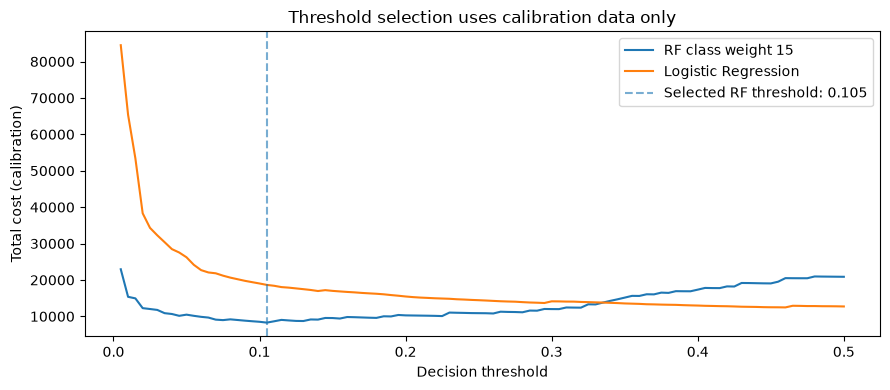

In [6]:
# Plot calibration costs only. We have not checked final validation yet.
fig, ax = plt.subplots(figsize=(9, 4))
rf_curve = rf_threshold_tables[selected_rf_name]
ax.plot(rf_curve["threshold"], rf_curve["cost"], label=selected_rf_name)
ax.plot(lr_threshold_table["threshold"], lr_threshold_table["cost"], label="Logistic Regression")
ax.axvline(
    selected_rf_threshold, linestyle="--", color="tab:blue", alpha=0.6,
    label=f"Selected RF threshold: {selected_rf_threshold:.3f}",
)
ax.set(
    xlabel="Decision threshold",
    ylabel="Total cost (calibration)",
    title="Threshold selection uses calibration data only",
)
ax.legend()
plt.tight_layout()
plt.show()


## 7. Final internal validation: the same rows for every model

**The Random Forest settings and decision threshold are now fixed.** We retrain the selected Random Forest on all 48,000 development rows, and retrain Logistic Regression on those same rows. We also include the unchanged Dummy baseline.

We compare five results: Dummy, Logistic Regression at 0.5, Logistic Regression with its calibrated threshold, Random Forest at 0.5, and Random Forest with its calibrated threshold. This shows the effect of both the **model choice** and the **threshold**.

We do not change any settings after looking at this validation result.


In [7]:
# Train the final internal models on development data only.
# Neither X_val nor the official test set is included in model fitting.
dummy = build_dummy_reference_classifier().fit(X_dev, y_dev)
lr_final = build_logistic_regression_pipeline(random_state=RANDOM_STATE)
lr_final.fit(X_dev, y_dev)
rf_final = build_random_forest(RF_VARIANTS[selected_rf_name])
rf_final.fit(X_dev, y_dev)

# Calculate scores for all three models on exactly the same validation rows.
dummy_prob = dummy.predict_proba(X_val)[:, 1]
lr_prob = lr_final.predict_proba(X_val)[:, 1]
rf_prob = rf_final.predict_proba(X_val)[:, 1]

# A threshold changes the prediction, but not the model's probability score.
validation_predictions = {
    "Dummy (majority class)": (dummy_prob >= 0.5).astype(int),
    "Logistic Regression 0.50": (lr_prob >= 0.5).astype(int),
    f"Logistic Regression {lr_threshold:.3f}": (lr_prob >= lr_threshold).astype(int),
    "Random Forest 0.50": (rf_prob >= 0.5).astype(int),
    f"Random Forest {selected_rf_threshold:.3f}": (rf_prob >= selected_rf_threshold).astype(int),
}
validation_probabilities = {
    "Dummy (majority class)": dummy_prob,
    "Logistic Regression 0.50": lr_prob,
    f"Logistic Regression {lr_threshold:.3f}": lr_prob,
    "Random Forest 0.50": rf_prob,
    f"Random Forest {selected_rf_threshold:.3f}": rf_prob,
}

# The group's existing evaluation function provides cost, TP, TN, FP, FN,
# recall, precision, F1, PR-AUC and accuracy for each model/threshold.
validation_metrics = {
    model_name: evaluate_binary_classifier(
        y_val, predictions, y_score=validation_probabilities[model_name]
    )
    for model_name, predictions in validation_predictions.items()
}
results = pd.DataFrame.from_dict(validation_metrics, orient="index")
results = results[["business_cost", "fn", "fp", "tp", "tn",
                   "recall", "precision", "f1", "pr_auc", "accuracy"]]
results.index.name = "Model and threshold"
results = results.sort_values("business_cost")

print("INTERNAL VALIDATION: 12,000 rows, including 200 APS failures")
print("Cost = 10 × FP + 500 × FN (lower is better)")
display(results.round(4))

# Double-check the business cost for each row of the comparison table.
for model_name in validation_predictions:
    score = validation_metrics[model_name]
    assert score["business_cost"] == FP_COST * score["fp"] + FN_COST * score["fn"]
assert len(y_val) == 12000 and int(y_val.sum()) == 200


INTERNAL VALIDATION: 12,000 rows, including 200 APS failures
Cost = 10 × FP + 500 × FN (lower is better)


,business_cost,fn,fp,tp,tn,recall,precision,f1,pr_auc,accuracy
Model and threshold,,,,,,,,,,
Random Forest 0.105,6660,6,366,194,11434,0.970,0.3464,0.5105,0.8778,0.9690
Logistic Regression 0.50,11640,16,364,184,11436,0.920,0.3358,0.4920,0.7202,0.9683
Logistic Regression 0.460,11830,16,383,184,11417,0.920,0.3245,0.4798,0.7202,0.9668
Random Forest 0.50,18090,35,59,165,11741,0.825,0.7366,0.7783,0.8778,0.9922
Dummy (majority class),100000,200,0,0,11800,0.000,0.0000,0.0000,0.0167,0.9833


## 8. Compare total cost and prediction errors

**False negative (FN):** a truck has an APS failure but is not flagged → cost 500.  
**False positive (FP):** a truck without an APS failure is flagged → cost 10.

To keep the figures easy to read, we plot **Logistic Regression with the default threshold** and **Random Forest with its selected threshold**. The table above includes the other options too.


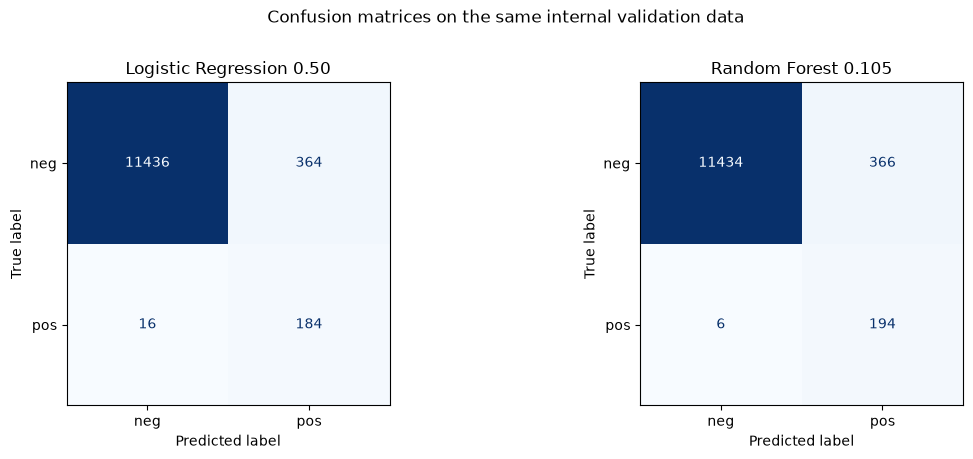

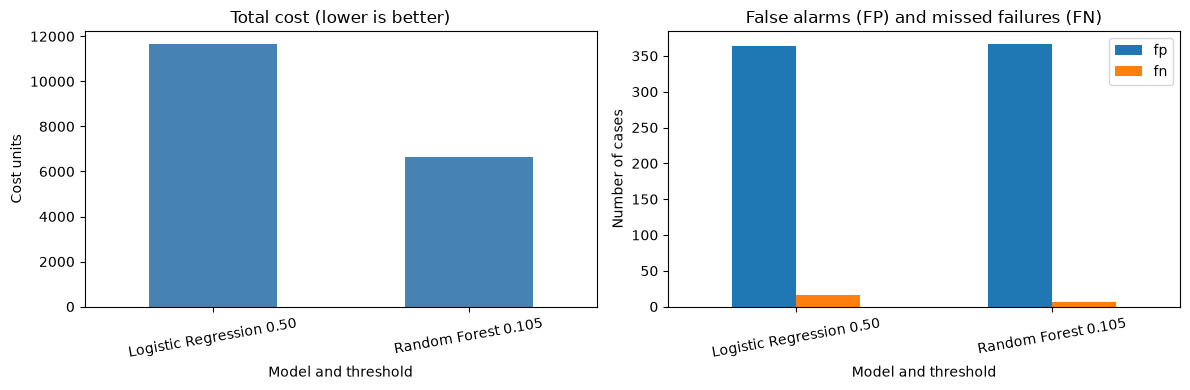

In [8]:
lr_name = "Logistic Regression 0.50"
rf_name = f"Random Forest {selected_rf_threshold:.3f}"

# A confusion matrix shows correct and incorrect predictions separately.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, model_name in zip(axes, [lr_name, rf_name]):
    ConfusionMatrixDisplay.from_predictions(
        y_val, validation_predictions[model_name], labels=[0, 1],
        display_labels=["neg", "pos"], ax=ax, cmap="Blues", colorbar=False,
    )
    ax.set_title(model_name)
plt.suptitle("Confusion matrices on the same internal validation data", y=1.01)
plt.tight_layout()
plt.show()

# Compare the total cost and the number of both types of mistakes.
comparison = results.loc[[lr_name, rf_name], ["business_cost", "fn", "fp"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison["business_cost"].plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Total cost (lower is better)")
axes[0].set_ylabel("Cost units")
comparison[["fp", "fn"]].plot.bar(ax=axes[1])
axes[1].set_title("False alarms (FP) and missed failures (FN)")
axes[1].set_ylabel("Number of cases")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=10)
plt.tight_layout()
plt.show()


## 9. A closer look at Random Forest errors

Besides looking at total cost, we want to understand **what kinds of errors** Random Forest makes. We count false positives and false negatives, show a few example rows, and compare how many sensor values are missing in each group.

This is a simple way to explore possible patterns in the errors. However, because the input features are anonymous, we **cannot identify the physical cause of a failure** or connect these rows to specific trucks.


In [9]:
# Keep the original row indexes so each prediction stays with its correct row.
# Even real APS failures can get a low model score, causing false negatives.
rf_errors = pd.DataFrame({
    "actual": y_val,
    "predicted": validation_predictions[rf_name],
    "APS_score": rf_prob,
    "missing_feature_values": X_val.isna().sum(axis=1),
}, index=X_val.index)

# Label the three outcomes to make the error tables easier to understand.
rf_errors["error_type"] = "Correct prediction"
rf_errors.loc[
    (rf_errors["actual"] == 1) & (rf_errors["predicted"] == 0), "error_type"
] = "FN: missed APS failure"
rf_errors.loc[
    (rf_errors["actual"] == 0) & (rf_errors["predicted"] == 1), "error_type"
] = "FP: unnecessary check"

print("Number of rows for each error type:")
display(rf_errors["error_type"].value_counts().to_frame("count"))
print("Example misclassified rows (without raw sensor values or identities):")
display(rf_errors.loc[rf_errors["error_type"] != "Correct prediction"].head(10).round(3))
print("Missing feature values per row, grouped by error type:")
display(rf_errors.groupby("error_type")["missing_feature_values"].agg(["count", "median", "mean"]).round(1))


Number of rows for each error type:


,count
error_type,
Correct prediction,11628
FP: unnecessary check,366
FN: missed APS failure,6


Example misclassified rows (without raw sensor values or identities):


,actual,predicted,APS_score,missing_feature_values,error_type
29074,0,1,0.635,60,FP: unnecessary check
7801,0,1,0.413,2,FP: unnecessary check
41883,0,1,0.230,2,FP: unnecessary check
35107,0,1,0.834,60,FP: unnecessary check
38682,0,1,0.195,26,FP: unnecessary check
29772,0,1,0.354,0,FP: unnecessary check
36090,0,1,0.106,2,FP: unnecessary check
5382,0,1,0.232,29,FP: unnecessary check
52950,0,1,0.344,28,FP: unnecessary check
33846,0,1,0.145,2,FP: unnecessary check


Missing feature values per row, grouped by error type:


,count,median,mean
error_type,,,
Correct prediction,11628,8.0,13.8
FN: missed APS failure,6,12.0,12.5
FP: unnecessary check,366,20.0,28.6


## 10. Precision–recall and feature importance

**PR-AUC** helps us see how well a model ranks rare APS failures across different thresholds. It does not depend on the one threshold we selected. We therefore show **one curve per model**, not two curves for different thresholds of the same model.

**Feature importance** shows which anonymous variables Random Forest uses most when splitting its trees. This does **not** prove that a specific truck component caused a failure. Correlated features can also share importance.


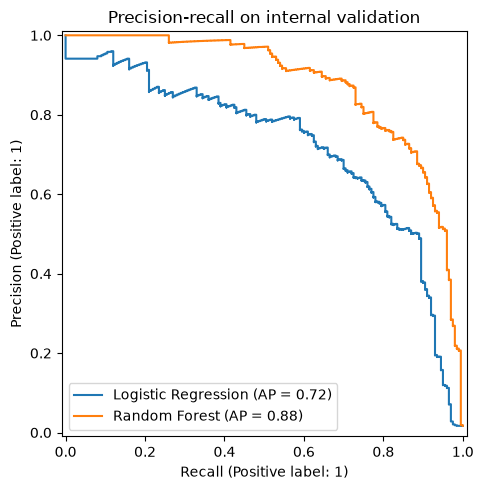

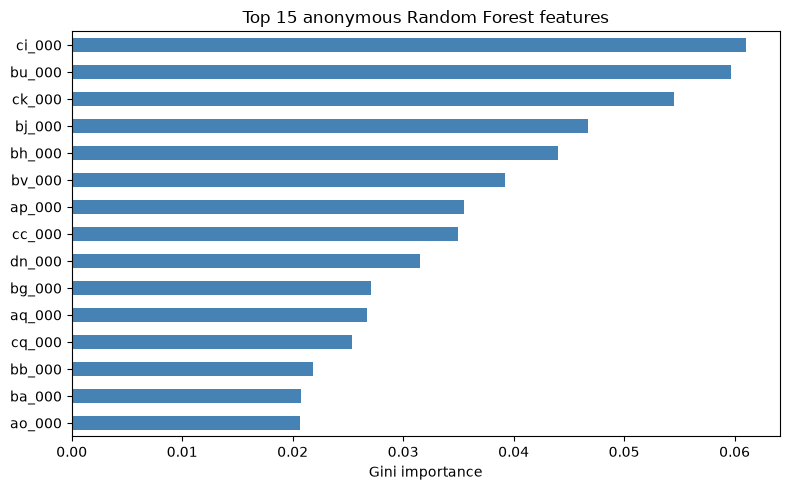

,Importance
ci_000,0.0611
bu_000,0.0596
ck_000,0.0545
bj_000,0.0467
bh_000,0.0440
bv_000,0.0392
ap_000,0.0355
cc_000,0.0350
dn_000,0.0315
bg_000,0.0271


In [10]:
# Both precision-recall curves use the same internal validation rows.
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_val, lr_prob, name="Logistic Regression", ax=ax)
PrecisionRecallDisplay.from_predictions(y_val, rf_prob, name="Random Forest", ax=ax)
ax.set_title("Precision-recall on internal validation")
plt.tight_layout()
plt.show()

# Retrieve the feature names after dropping cd_000 and adding missing indicators.
# SimpleImputer gives its missing-value indicator columns their own names.
features_after_drop = rf_final.named_steps["drop_constant"].transform(X_dev).columns
feature_names = rf_final.named_steps["imputer"].get_feature_names_out(features_after_drop)
importances = pd.Series(
    rf_final.named_steps["classifier"].feature_importances_,
    index=feature_names, name="Importance",
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
importances.head(15).iloc[::-1].plot.barh(ax=ax, color="steelblue")
ax.set(title="Top 15 anonymous Random Forest features", xlabel="Gini importance")
plt.tight_layout()
plt.show()
display(importances.head(15).to_frame().round(4))


## 11. Results, interpretation and handover

This final code cell prints a short conclusion using **the results actually calculated above**. It does not choose a different model after looking at validation data.

Logistic Regression at threshold 0.5 is the group's original baseline. We also include Logistic Regression with its calibrated threshold to keep the comparison fair.


In [11]:
rf_scores = validation_metrics[rf_name]
lr_scores = validation_metrics[lr_name]
lr_tuned_name = f"Logistic Regression {lr_threshold:.3f}"
lr_tuned_scores = validation_metrics[lr_tuned_name]

# A positive cost difference means that Random Forest costs less than LR 0.5.
cost_difference = lr_scores["business_cost"] - rf_scores["business_cost"]
improvement_percent = cost_difference / lr_scores["business_cost"] * 100

print("RESULTS AND INTERPRETATION (internal validation only)")
print(f"Selected RF: {selected_rf_name}, threshold {selected_rf_threshold:.3f}")
print(f"Logistic Regression 0.50: cost {lr_scores['business_cost']:,}, "
      f"FN {lr_scores['fn']}, FP {lr_scores['fp']}")
print(f"Logistic Regression {lr_threshold:.3f}: cost {lr_tuned_scores['business_cost']:,}, "
      f"FN {lr_tuned_scores['fn']}, FP {lr_tuned_scores['fp']}")
print(f"Random Forest {selected_rf_threshold:.3f}: cost {rf_scores['business_cost']:,}, "
      f"FN {rf_scores['fn']}, FP {rf_scores['fp']}")

if cost_difference > 0:
    print(f"RF reduced cost by {cost_difference:,} ({improvement_percent:.1f}%) "
          "compared with LR at the default threshold on this validation set.")
elif cost_difference < 0:
    print(f"RF cost {-cost_difference:,} more than LR at the default threshold "
          "on this validation set.")
else:
    print("RF and LR had the same cost on this validation set.")

print("\nLimitations: only one stratified validation split and around 200 positive cases "
      "in validation. Calibration results can be optimistic. "
      "The conclusion should be checked on the official test set at the end.")
print("Note: results may differ from saved outputs in notebook 02 if they were "
      "run in a different environment or at another time. Here both models "
      "were retrained and compared on exactly the same validation rows.")


RESULTS AND INTERPRETATION (internal validation only)
Selected RF: RF class weight 15, threshold 0.105
Logistic Regression 0.50: cost 11,640, FN 16, FP 364
Logistic Regression 0.460: cost 11,830, FN 16, FP 383
Random Forest 0.105: cost 6,660, FN 6, FP 366
RF reduced cost by 4,980 (42.8%) compared with LR at the default threshold on this validation set.

Limitations: only one stratified validation split and around 200 positive cases in validation. Calibration results can be optimistic. The conclusion should be checked on the official test set at the end.
Note: results may differ from saved outputs in notebook 02 if they were run in a different environment or at another time. Here both models were retrained and compared on exactly the same validation rows.


### Limitations and points to share with the group

- **Internal validation only:** the official test set has **not** been opened. We do not use it for further parameter or threshold experiments. When the group has agreed on the final settings, the selected model can be trained on all the official training data and evaluated **once** on the official test set.
- **Same data split and consistent preprocessing rules:** Dummy and Logistic Regression use the group's existing functions. Random Forest uses median imputation and missing-value indicators, but no scaling because trees do not need it. Any learned preprocessing is fitted inside a pipeline.
- **Cost matters more than accuracy:** a missed APS failure costs 500 and an unnecessary check costs 10. Better recall often means more false alarms. Our results show that trade-off.
- **Be careful with conclusions:** only 200 positive examples are present in the validation set. A few extra missed failures could change the cost a lot. This is one comparison on one split, not proof that one method is always better. Calibration cost should **not** be presented as an unbiased final result.
- **No physical diagnosis:** the 170 anonymous input variables cannot tell us which actual components caused the failures or when a truck will break down.
- **Reproducibility:** the settings, random seeds and experiments are included here. Run this notebook from the project root or `notebooks/` after placing `aps_failure_training_set.csv` in `data/raw/`. No extra packages are needed beyond the group's `requirements.txt`.
